# 实验四 B 多层 LSTM 与 BiLSTM 中文情感三分类

使用要求指定的 [Chinese Multi Emotion Dialogue Dataset](https://huggingface.co/datasets/Johnson8187/Chinese_Multi-Emotion_Dialogue_Dataset)。实际 CSV 的八个标签以本地统计为准；数据卡中的类别说明和统计存在不一致。本实验先繁转简，再进行显式的八类到三类映射，使用字符级 Embedding，对比两层单向 LSTM 和单层双向 LSTM。

开心→积极；悲伤、愤怒、厌恶→消极；平淡、疑问、关切、惊奇→中性。关切和惊奇的情感极性依赖语境，这种映射是本实验为满足三分类采用的约定，不能视作人工重新标注后的精确情感真值。

In [1]:
from pathlib import Path
import random, json, copy, time, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Dataset

ROOT = Path.cwd() if (Path.cwd() / "exp4").is_dir() else Path.cwd().parent
BASE = ROOT / "exp4"
DATA = BASE / "data"
CACHE = BASE / ".cache" / "exp4B"
RESULT = BASE / "results" / "exp4B"
for folder in [DATA, CACHE, RESULT]:
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
                     "axes.unicode_minus": False, "figure.dpi": 110})
print("Python:", sys.executable, "设备:", device)

Python: D:\Anaconda\python.exe 设备: cpu


## 1 繁简转换 清洗与划分

In [2]:
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import re, requests
local_packages = BASE / ".cache/python"
if local_packages.exists(): sys.path.insert(0,str(local_packages))
from opencc import OpenCC
converter = OpenCC("t2s")
raw_path = DATA / "emotion_raw.csv"
if not raw_path.exists():
    r=requests.get("https://huggingface.co/datasets/Johnson8187/Chinese_Multi-Emotion_Dialogue_Dataset/resolve/main/data.csv",timeout=60)
    r.raise_for_status();raw_path.write_bytes(r.content)
raw_df=pd.read_csv(raw_path)
df=raw_df.dropna(subset=["text","emotion"]).copy()
df["text_simplified"]=df.text.map(lambda x: re.sub(r"\s+","",converter.convert(str(x))).strip())
mapping={"开心语调":0,"悲伤语调":1,"愤怒语调":1,"厌恶语调":1,
         "平淡语气":2,"疑问语调":2,"关切语调":2,"惊奇语调":2}
df["label"]=df.emotion.map(converter.convert).map(mapping)
assert df.label.notna().all(), "发现未映射标签"
df=df[df.text_simplified.str.len()>0].copy()
# 同一简体文本不能跨集合；冲突标签的文本全部排除。
conflicts=df.groupby("text_simplified").label.nunique()
df=df[~df.text_simplified.isin(conflicts[conflicts>1].index)].drop_duplicates("text_simplified").reset_index(drop=True)
names=["积极","消极","中性"]
df["label"]=df.label.astype(int)
train_ids,remain_ids=train_test_split(np.arange(len(df)),test_size=0.3,stratify=df.label,random_state=SEED)
val_ids,test_ids=train_test_split(remain_ids,test_size=0.5,stratify=df.loc[remain_ids,"label"],random_state=SEED)
df["split"]="train";df.loc[val_ids,"split"]="val";df.loc[test_ids,"split"]="test"
df.to_csv(RESULT/"data_split.csv",index=False,encoding="utf-8-sig")
pd.DataFrame([{"original_simplified":k,"target":names[v]} for k,v in mapping.items()]).to_csv(RESULT/"label_mapping.csv",index=False,encoding="utf-8-sig")
display(pd.crosstab(df.split,df.label).rename(columns=dict(enumerate(names))).reindex(["train","val","test"]))
print("原始行数",len(raw_df),"清洗后",len(df),"冲突文本数",sum(conflicts>1))
display(df[["text","text_simplified","emotion"]].head())

label,积极,消极,中性
split,,,
train,413,992,1502
val,89,212,322
test,89,213,322


原始行数 4159 清洗后 4154 冲突文本数 0


,text,text_simplified,emotion
0,你要不要去吃午餐？,你要不要去吃午餐？,平淡語氣
1,誒誒誒！我甄選上了！,诶诶诶！我甄选上了！,開心語調
2,我幾天身體好像有點不太舒服，肚子好痛,我几天身体好像有点不太舒服，肚子好痛,悲傷語調
3,我的小專題組員都不做事，幹!超後悔跟他一組,我的小专题组员都不做事，干!超后悔跟他一组,憤怒語調
4,他們是不是吵架了？不會打起來吧？,他们是不是吵架了？不会打起来吧？,平淡語氣


## 2 字符向量与网络结构

词表只从训练集建立，频次至少 2；PAD=0，UNK=1。使用字符作为分词单元，不依赖外部分词器；序列最多 64 字，截断尾部，右侧补 PAD。Embedding 为 96 维。Stacked LSTM 有两层，每层 64 单元、层间 dropout=0.2；BiLSTM 有一层，每方向 64 单元。取最后有效隐藏状态，经 dropout=0.3 与线性层输出三类。使用 pack_padded_sequence 避免补零改变最后状态。

两个模型使用相同划分和随机种子，Adam 学习率 0.002，batch=64，最多 30 轮。交叉熵按训练类别逆频率加权；验证宏平均 F1 连续 6 轮没有提高时提前停止。参数量分别打印，结构参数不同，因此比较不能单独归因于双向性。

In [3]:
counter=Counter("".join(df.loc[train_ids,"text_simplified"]))
vocab={"<pad>":0,"<unk>":1}
vocab.update({c:i+2 for i,(c,n) in enumerate(sorted((c,n) for c,n in counter.items() if n>=2))})
MAX_LEN=64
X=torch.zeros((len(df),MAX_LEN),dtype=torch.long)
lengths=torch.zeros(len(df),dtype=torch.long)
for i,text in enumerate(df.text_simplified):
    ids=[vocab.get(c,1) for c in text[:MAX_LEN]]
    X[i,:len(ids)]=torch.tensor(ids);lengths[i]=len(ids)
y=torch.tensor(df.label.to_numpy(),dtype=torch.long)
loaders={}
for split,ids in [("train",train_ids),("val",val_ids),("test",test_ids)]:
    loaders[split]=DataLoader(TensorDataset(X[ids],lengths[ids],y[ids]),batch_size=64,shuffle=split=="train",num_workers=0,generator=torch.Generator().manual_seed(SEED))
(CACHE/"vocab.json").write_text(json.dumps(vocab,ensure_ascii=False),encoding="utf-8")
print("词表大小",len(vocab),"截断文本数",int((df.text_simplified.str.len()>MAX_LEN).sum()))

class SentimentNet(nn.Module):
    def __init__(self,bidirectional=False):
        super().__init__()
        self.bidirectional=bidirectional
        self.embedding=nn.Embedding(len(vocab),96,padding_idx=0)
        self.lstm=nn.LSTM(96,64,num_layers=1 if bidirectional else 2,bidirectional=bidirectional,batch_first=True,dropout=0 if bidirectional else 0.2)
        self.classifier=nn.Sequential(nn.Dropout(0.3),nn.Linear(128 if bidirectional else 64,3))
    def forward(self,x,length):
        e=self.embedding(x)
        p=nn.utils.rnn.pack_padded_sequence(e,length.cpu(),batch_first=True,enforce_sorted=False)
        _,(h,_)=self.lstm(p)
        last=torch.cat([h[-2],h[-1]],dim=1) if self.bidirectional else h[-1]
        return self.classifier(last)

weights=len(train_ids)/(3*np.bincount(df.loc[train_ids,"label"],minlength=3))
criterion=nn.CrossEntropyLoss(weight=torch.tensor(weights,dtype=torch.float32,device=device),reduction="none")
def epoch_sentiment(model,loader,optimizer=None):
    model.train(optimizer is not None);loss_sum=0;truth=[];pred=[]
    with torch.set_grad_enabled(optimizer is not None):
        for x,l,y in loader:
            x,y=x.to(device),y.to(device)
            logits=model(x,l);losses=criterion(logits,y);loss=losses.mean()
            if optimizer is not None:
                optimizer.zero_grad();loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()
            loss_sum+=losses.sum().item();truth.extend(y.cpu().tolist());pred.extend(logits.argmax(1).cpu().tolist())
    p,r,f,_=precision_recall_fscore_support(truth,pred,labels=range(3),average="macro",zero_division=0)
    return loss_sum/len(truth),accuracy_score(truth,pred),p,r,f,np.array(pred)

records=[];metrics=[];all_pred={}
for name,bidirectional in [("Stacked LSTM",False),("BiLSTM",True)]:
    torch.manual_seed(SEED)
    model=SentimentNet(bidirectional).to(device)
    print(name,"参数量",sum(p.numel() for p in model.parameters()))
    optimizer=torch.optim.Adam(model.parameters(),lr=0.002,weight_decay=1e-4)
    best,stale,state,best_epoch=-1,0,None,0
    for epoch in range(1,31):
        train=epoch_sentiment(model,loaders["train"],optimizer);val=epoch_sentiment(model,loaders["val"])
        records.append(dict(model=name,epoch=epoch,train_loss=train[0],val_loss=val[0],train_accuracy=train[1],val_accuracy=val[1],val_macro_f1=val[4]))
        if val[4]>best+1e-4:
            best,stale,state,best_epoch=val[4],0,copy.deepcopy(model.state_dict()),epoch
        else:stale+=1
        if epoch%5==0:print(name,epoch,"验证 F1",round(val[4],4),flush=True)
        if stale>=6:break
    model.load_state_dict(state)
    result=epoch_sentiment(model,loaders["test"])
    all_pred[name]=result[-1]
    metrics.append(dict(model=name,Accuracy=result[1],Precision_macro=result[2],Recall_macro=result[3],F1_macro=result[4],best_epoch=best_epoch,parameters=sum(p.numel() for p in model.parameters())))
    report=classification_report(df.loc[test_ids,"label"],result[-1],labels=range(3),target_names=names,output_dict=True,zero_division=0)
    pd.DataFrame(report).T.to_csv(RESULT/(name.replace(" ","_")+"_class_metrics.csv"),encoding="utf-8-sig")
    torch.save(state,CACHE/(name.replace(" ","_")+".pth"))
history=pd.DataFrame(records);metric_df=pd.DataFrame(metrics)
history.to_csv(RESULT/"training_history.csv",index=False)
metric_df.to_csv(RESULT/"metrics.csv",index=False,encoding="utf-8-sig")
prediction_df=df.loc[test_ids,["text_simplified","emotion","label"]].copy()
prediction_df["true_sentiment"]=[names[i] for i in prediction_df.label]
for name,pred in all_pred.items():prediction_df[name]=[names[i] for i in pred]
prediction_df.to_csv(RESULT/"test_predictions.csv",index=False,encoding="utf-8-sig")
display(metric_df.round(4))

词表大小 1204 截断文本数 42
Stacked LSTM 参数量 190531


Stacked LSTM 5 验证 F1 0.7919


Stacked LSTM 10 验证 F1 0.8353


Stacked LSTM 15 验证 F1 0.8337


BiLSTM 参数量 198915


BiLSTM 5 验证 F1 0.8058


BiLSTM 10 验证 F1 0.8403


BiLSTM 15 验证 F1 0.8305


,model,Accuracy,Precision_macro,Recall_macro,F1_macro,best_epoch,parameters
0,Stacked LSTM,0.8766,0.8645,0.8615,0.8630,10,190531
1,BiLSTM,0.8750,0.8584,0.8638,0.8609,9,198915


## 3 训练曲线 混淆矩阵与预测样例

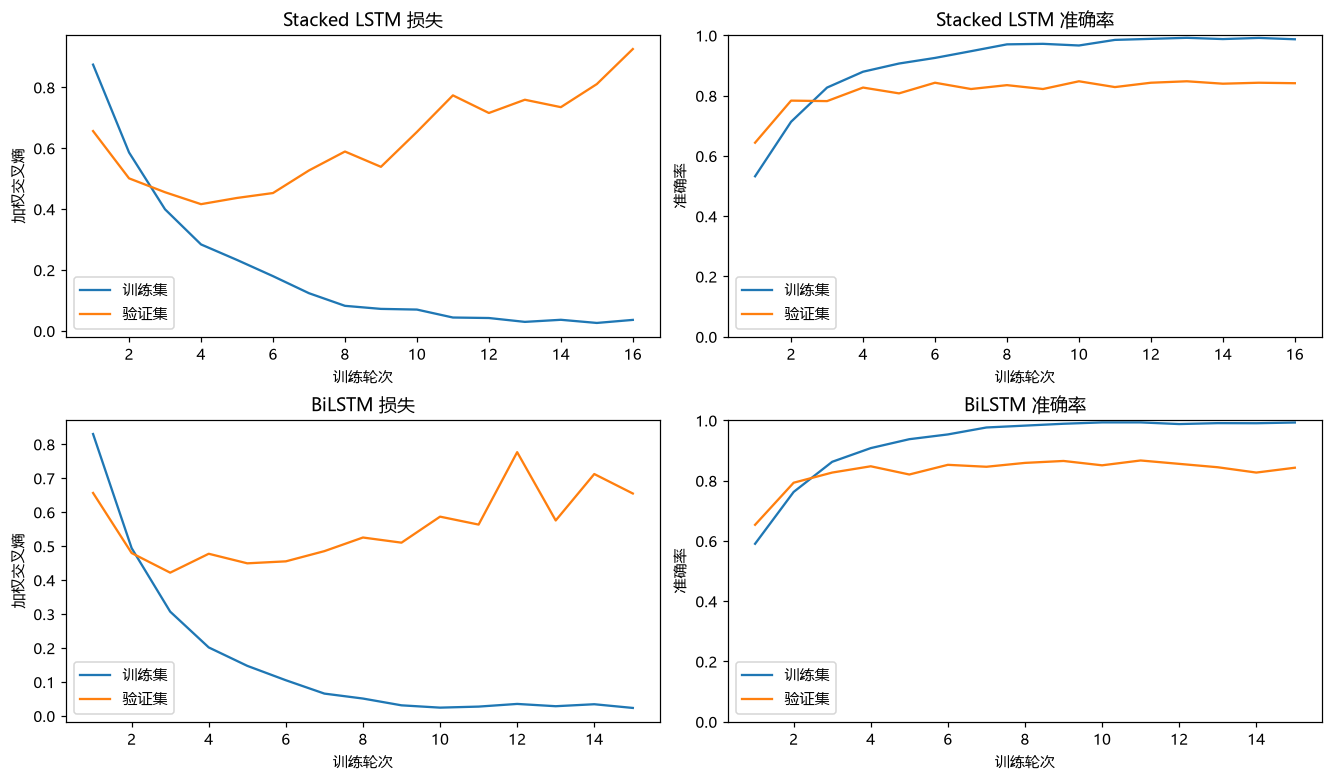

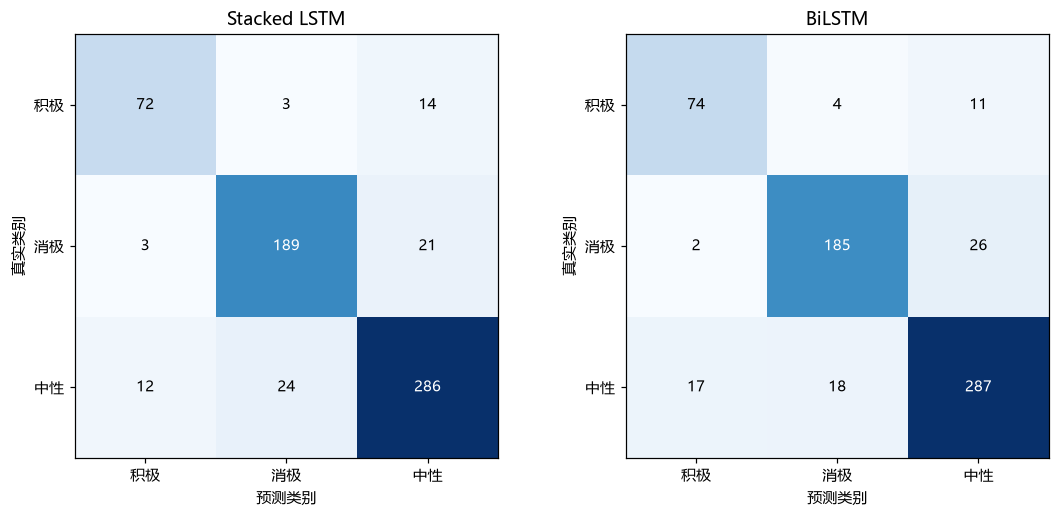

,text_simplified,emotion,true_sentiment,Stacked LSTM,BiLSTM
3481,当然可以啦，你最近心情怎么样呢？,開心語調,积极,中性,中性
3698,你怎么这么贴心，这真是我收到过最棒的礼物！,開心語調,积极,积极,积极
2829,你说这些话有没有想过别人的感受？真的是让我无法容忍，完全没在顾及其他人！,憤怒語調,消极,消极,消极
1177,我明知道这样不对，可还是忍不住流眼泪。,悲傷語調,消极,消极,消极
360,我有点怕明天的面试，不知道自己准备得够不够。,平淡語氣,中性,中性,中性
1673,外面下著雨，我坐在窗边，看著路上的行人。,平淡語氣,中性,中性,中性


,text_simplified,emotion,label,true_sentiment,Stacked LSTM,BiLSTM
3481,当然可以啦，你最近心情怎么样呢？,開心語調,0,积极,中性,中性
1781,这里的每个角落，都有我们曾经的回忆。,悲傷語調,1,消极,中性,中性
3862,明明可以有更好的结果，为什么会变成这样？,悲傷語調,1,消极,消极,中性
2310,为什么你总是这么冷漠，我怎么努力也换不来一点关心！,憤怒語調,1,消极,消极,中性
3884,他们做错的事情，凭什么让我们承担后果？,憤怒語調,1,消极,中性,中性
700,我最近好常加班...不知道老板到底想怎么样。,平淡語氣,2,中性,消极,消极
3827,那个瞬间，整个场景简直就像电影一样！,驚奇語調,2,中性,中性,积极
548,干我今天基本电学考得超烂,憤怒語調,1,消极,积极,积极


In [4]:
fig,axes=plt.subplots(2,2,figsize=(12,7),constrained_layout=True)
for row,(name,part) in enumerate(history.groupby("model",sort=False)):
    axes[row,0].plot(part.epoch,part.train_loss,label="训练集");axes[row,0].plot(part.epoch,part.val_loss,label="验证集")
    axes[row,0].set(title=name+" 损失",xlabel="训练轮次",ylabel="加权交叉熵")
    axes[row,1].plot(part.epoch,part.train_accuracy,label="训练集");axes[row,1].plot(part.epoch,part.val_accuracy,label="验证集")
    axes[row,1].set(title=name+" 准确率",xlabel="训练轮次",ylabel="准确率",ylim=(0,1))
for ax in axes.flat:ax.legend()
fig.savefig(RESULT/"training_curves.png",dpi=180);plt.show()

fig,axes=plt.subplots(1,2,figsize=(10,4.6),constrained_layout=True)
for ax,(name,pred) in zip(axes,all_pred.items()):
    cm=confusion_matrix(df.loc[test_ids,"label"],pred,labels=range(3))
    ax.imshow(cm,cmap="Blues")
    ax.set(xticks=range(3),yticks=range(3),xticklabels=names,yticklabels=names,xlabel="预测类别",ylabel="真实类别",title=name)
    for i in range(3):
        for j in range(3):ax.text(j,i,str(cm[i,j]),ha="center",va="center",color="white" if cm[i,j]>cm.max()/2 else "black")
fig.savefig(RESULT/"confusion_matrices.png",dpi=180);plt.show()
# 每类取测试清单中最先出现的两条，不根据预测好坏挑样本。
example_ids=[]
for c in range(3):example_ids.extend(prediction_df[prediction_df.label==c].index[:2])
display(prediction_df.loc[example_ids].drop(columns="label"))
display(prediction_df[prediction_df["true_sentiment"]!=prediction_df["BiLSTM"]].head(8))

## 分析依据与限制

结合实际 metrics.csv、学习曲线和混淆矩阵比较两种模型，保留错误预测。双向结构可以利用整句前后文，但本实验同时改变了层数与参数量，单次随机划分的差异不能证明结构本身在所有数据上有优势。数据包含合成对话及类别映射误差；按文本去重能避免完全相同样本跨集合，但相似句式仍可能跨集合，因此不把结果外推为真实对话系统的性能。

代码截图可直接截取上方 SentimentNet 和训练单元格，结果截图可用内嵌表格、训练曲线和混淆矩阵。

本次多层 LSTM 的测试准确率为 0.8766、宏平均 F1 为 0.8630；BiLSTM 为 0.8750 和 0.8609，差距很小。曲线中训练准确率接近 1，而验证损失在前几轮后回升，存在明显过拟合。权重按验证宏平均 F1 选择，分别来自第 10 轮和第 9 轮；不能用最后一轮的验证损失解释被选模型的成绩。